In [4]:
!pip install CatBoost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.7 MB/s  0:00:10


In [5]:
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, auc, confusion_matrix,
    precision_recall_curve, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42
TARGET = "default_12m"
OUT_DIR = Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [6]:
# inn читаем как строку, чтобы не потерять ведущие нули
df = pd.read_csv("applications.csv", dtype={"inn": str})
print(f"Загружено: {df.shape[0]} строк, {df.shape[1]} столбцов")
df.head()

Загружено: 100000 строк, 47 столбцов


,application_id,application_date,inn,legal_form,region_code,okved_group,registration_date,business_age_months,employees,tax_regime,owner_age,registry_status,mass_address_flag,disqualified_person_flag,revenue_12m,net_profit_12m,avg_monthly_account_turnover,turnover_trend_6m,revenue_seasonality_cv,neg_balance_days_share_12m,total_assets,equity_ratio,current_ratio,tax_arrears_flag,court_cases_12m,existing_debt_total,existing_monthly_payment,bki_active_loans,bki_score,bki_history_months,bki_overdue_90_24m,bki_max_overdue_days_24m,bki_inquiries_6m,owners_count,owner_max_share_pct,director_is_owner,product_code,amount_rub,term_months,indicative_rate_pct,purpose,collateral_type,collateral_value_rub,owner_guarantee,monthly_payment_rub,dscr,default_12m
0,APP-0000001,2023-10-22,785571502879,IP,78,49,2020-02-20,44,0,USN_6,47,active,0,0,17334809.0,1480679.0,1567760.0,0.0398,0.0939,0.0771,NaN,NaN,NaN,0,1.0,2233420.0,84738.0,4,553.0,63,0,0,1.0,NaN,NaN,NaN,COMM_MORTGAGE,3000000.0,180,20.6,real_estate,real_estate,4817836.0,NaN,54134.0,1.097,0
1,APP-0000002,2023-10-22,506387022354,IP,50,46,2023-04-22,6,0,USN_15,35,active,0,0,1205996.0,-101588.0,98312.0,-0.1667,0.1469,0.1505,NaN,NaN,NaN,0,0.0,0.0,0.0,0,430.0,84,0,0,2.0,NaN,NaN,NaN,COMM_MORTGAGE,3000000.0,120,19.2,real_estate,real_estate,2979817.0,NaN,56433.0,-0.114,1
2,APP-0000003,2023-10-22,502902566916,IP,50,96,2021-09-21,25,0,USN_15,56,active,0,0,4247835.0,1020235.0,369109.0,0.5306,0.0929,0.0411,NaN,NaN,NaN,0,0.0,921686.0,32544.0,1,598.0,107,0,0,0.0,NaN,NaN,NaN,OVERDRAFT,220000.0,12,23.6,working_capital,vehicle,409290.0,NaN,4330.0,2.498,0
3,APP-0000004,2023-10-22,6359906220,OOO,63,47,2022-10-21,12,22,OSNO,43,active,0,0,60139515.0,8338901.0,6737707.0,-0.2760,0.2940,0.0011,31139659.0,0.5561,0.845,0,0.0,0.0,0.0,0,500.0,21,1,148,3.0,2.0,74.0,1.0,WC_LOAN,10530000.0,36,21.0,working_capital,inventory,13210194.0,1.0,396888.0,2.003,0
4,APP-0000005,2023-10-22,771876472569,IP,77,49,2016-05-22,89,0,USN_6,42,active,0,0,4566664.0,853691.0,309708.0,0.2071,0.1481,0.0468,NaN,NaN,NaN,0,0.0,0.0,0.0,0,573.0,146,0,0,1.0,NaN,NaN,NaN,OVERDRAFT,450000.0,12,21.6,working_capital,none,0.0,NaN,8105.0,9.717,0


In [7]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=False),
}).sort_values(["missing_pct", "n_unique"], ascending=[False, True])
display(info)

print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов application_id:", df["application_id"].duplicated().sum())
print(df[TARGET].value_counts(dropna=False))

,dtype,missing,missing_pct,n_unique
director_is_owner,float64,45051,45.05,3
owner_guarantee,float64,45051,45.05,3
owners_count,float64,45051,45.05,5
owner_max_share_pct,float64,45051,45.05,59
current_ratio,float64,45051,45.05,3346
equity_ratio,float64,45051,45.05,8734
total_assets,float64,45051,45.05,54937
bki_score,float64,4607,4.61,525
revenue_seasonality_cv,float64,2032,2.03,6873
avg_monthly_account_turnover,float64,2013,2.01,97108


Полных дубликатов: 0
Дубликатов application_id: 0
default_12m
0    94949
1     5051
Name: count, dtype: int64


In [8]:
df = df.drop_duplicates()
df = df[df[TARGET].notna()].copy()
df[TARGET] = df[TARGET].astype(int)
print("Размер после очистки:", df.shape)

Размер после очистки: (100000, 47)


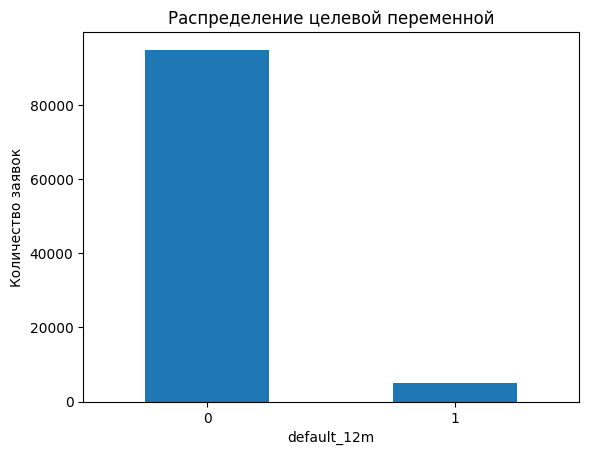

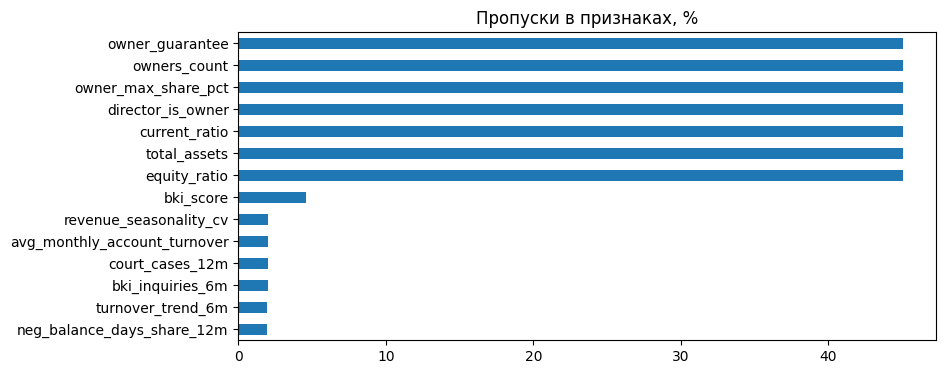

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
application_id,100000,100000,APP-0099984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
application_date,100000,1095,2026-09-19,122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
inn,100000,99983,7796549630,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
legal_form,100000,2,OOO,54949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region_code,100000.0,NaN,NaN,NaN,52.96009,22.328221,2.0,36.0,55.0,77.0,78.0
okved_group,100000,12,47,20511,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registration_date,100000,9499,2023-03-28,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
business_age_months,100000.0,NaN,NaN,NaN,63.38253,66.044531,3.0,20.0,42.0,81.0,360.0
employees,100000.0,NaN,NaN,NaN,12.51549,18.757927,0.0,1.0,5.0,15.0,100.0
tax_regime,100000,4,USN_6,41058,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
ax = df[TARGET].value_counts().sort_index().plot(kind="bar", rot=0)
ax.set_title("Распределение целевой переменной")
ax.set_xlabel(TARGET)
ax.set_ylabel("Количество заявок")
plt.show()

missing = (df.isna().mean() * 100).sort_values()
missing = missing[missing > 0]
ax = missing.plot(kind="barh", figsize=(9, max(4, len(missing) * 0.25)))
ax.set_title("Пропуски в признаках, %")
plt.show()

df.describe(include="all").T

In [10]:
data = df.set_index("application_id")

data["is_ip"] = (data["legal_form"] == "IP").astype(int)

# у ИП нет баланса и учредителей, поэтому пропуски в этих полях заполняем нулями
OOO_ONLY_COLS = ["total_assets", "equity_ratio", "owners_count", "owner_max_share_pct", "current_ratio"]
data[OOO_ONLY_COLS] = data[OOO_ONLY_COLS].fillna(0)

data["application_date"] = pd.to_datetime(data["application_date"])
data["registration_date"] = pd.to_datetime(data["registration_date"])

data["registry_status"] = data["registry_status"].str.lower().str.strip()
data["is_liquidation"] = (data["registry_status"] == "liquidation").astype(int)
data["is_reorganization"] = (data["registry_status"] == "reorganization").astype(int)
data["is_active_business"] = (data["registry_status"] == "active").astype(int)

# возраст бизнеса пересчитываем по датам, если результат выглядит правдоподобно
age_calc = (data["application_date"] - data["registration_date"]).dt.days / 30.44
data["business_age_months"] = age_calc.where(age_calc.between(0, 600), data["business_age_months"]).clip(lower=0)

data["bki_overdue_90_24m"] = data["bki_overdue_90_24m"].fillna(0)
data["bki_overdue_90_24m_flag"] = (data["bki_overdue_90_24m"] > 0).astype(int)

data["okved_group"] = data["okved_group"].astype(str).str.replace("-", "_").str.strip()

In [11]:
data["fin_data_missing"] = data[[
    "revenue_seasonality_cv", "turnover_trend_6m",
    "avg_monthly_account_turnover", "neg_balance_days_share_12m",
]].isna().any(axis=1).astype(int)
data["bki_missing"] = data["bki_score"].isna().astype(int)
data["bki_inquiries_missing"] = data["bki_inquiries_6m"].isna().astype(int)

# пустое значение означает, что судов не было
data["court_cases_missing"] = data["court_cases_12m"].isna().astype(int)
data["court_cases_12m"] = data["court_cases_12m"].fillna(0)

In [12]:
eps = 1e-6
revenue = data["revenue_12m"].fillna(0).clip(lower=eps)
revenue_month = (data["revenue_12m"].fillna(0) / 12).clip(lower=eps)
turnover = data["avg_monthly_account_turnover"].fillna(0).clip(lower=eps)
employees = data["employees"].fillna(0).clip(lower=1)

data["has_zero_turnover"] = (data["avg_monthly_account_turnover"].fillna(0) <= 0).astype(int)

data["debt_to_revenue"] = data["existing_debt_total"] / revenue
data["payment_to_turnover"] = data["existing_monthly_payment"] / turnover
data["new_payment_to_revenue"] = data["monthly_payment_rub"] / revenue_month

data["collateral_coverage"] = data["collateral_value_rub"] / (data["amount_rub"] + eps)
data["has_collateral"] = (data["collateral_value_rub"] > 0).astype(int)

data["profit_margin"] = data["net_profit_12m"] / revenue
data["turnover_to_revenue"] = data["avg_monthly_account_turnover"] / revenue_month

data["employees_is_zero"] = (data["employees"].fillna(0) == 0).astype(int)
data["revenue_per_employee"] = data["revenue_12m"] / employees
data["debt_per_employee"] = data["existing_debt_total"] / employees

data["is_young_business"] = (data["business_age_months"] < 12).astype(int)
data["is_very_young_business"] = (data["business_age_months"] < 6).astype(int)
data["has_negative_profit"] = (data["net_profit_12m"] < 0).astype(int)
data["has_negative_trend"] = (data["turnover_trend_6m"] < 0).astype(int)
data["high_seasonality"] = (data["revenue_seasonality_cv"] > 0.5).astype(int)

data["bki_max_overdue_days_log"] = np.log1p(data["bki_max_overdue_days_24m"].fillna(0).clip(lower=0))
data["bki_many_inquiries"] = (data["bki_inquiries_6m"].fillna(0) >= 3).astype(int)

data["ip_personal_collateral"] = ((data["is_ip"] == 1) & (data["collateral_type"] == "real_estate")).astype(int)

data["amount_to_revenue"] = data["amount_rub"] / revenue
data["amount_to_turnover"] = data["amount_rub"] / turnover

In [13]:
# dscr и monthly_payment_rub зависят от параметров уже одобренного кредита
LEAKAGE_COLS = ["dscr", "monthly_payment_rub"]
DROP_COLS = [TARGET, "inn", "application_date", "registration_date", "registry_status"] + LEAKAGE_COLS

y = data[TARGET]
X = data.drop(columns=DROP_COLS)

constant_cols = [c for c in X.columns if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_cols)
print("Удалены константные признаки:", constant_cols)

print("X:", X.shape, "y:", y.shape)
print(X.dtypes.value_counts())
X.head()

Удалены константные признаки: []
X: (100000, 69) y: (100000,)
float64    33
int64      30
object      6
Name: count, dtype: int64


,legal_form,region_code,okved_group,business_age_months,employees,tax_regime,owner_age,mass_address_flag,disqualified_person_flag,revenue_12m,net_profit_12m,avg_monthly_account_turnover,turnover_trend_6m,revenue_seasonality_cv,neg_balance_days_share_12m,total_assets,equity_ratio,current_ratio,tax_arrears_flag,court_cases_12m,existing_debt_total,existing_monthly_payment,bki_active_loans,bki_score,bki_history_months,bki_overdue_90_24m,bki_max_overdue_days_24m,bki_inquiries_6m,owners_count,owner_max_share_pct,director_is_owner,product_code,amount_rub,term_months,indicative_rate_pct,purpose,collateral_type,collateral_value_rub,owner_guarantee,is_ip,is_liquidation,is_reorganization,is_active_business,bki_overdue_90_24m_flag,fin_data_missing,bki_missing,bki_inquiries_missing,court_cases_missing,has_zero_turnover,debt_to_revenue,payment_to_turnover,new_payment_to_revenue,collateral_coverage,has_collateral,profit_margin,turnover_to_revenue,employees_is_zero,revenue_per_employee,debt_per_employee,is_young_business,is_very_young_business,has_negative_profit,has_negative_trend,high_seasonality,bki_max_overdue_days_log,bki_many_inquiries,ip_personal_collateral,amount_to_revenue,amount_to_turnover
application_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
APP-0000001,IP,78,49,44.021025,0,USN_6,47,0,0,17334809.0,1480679.0,1567760.0,0.0398,0.0939,0.0771,0.0,0.0000,0.000,0,1.0,2233420.0,84738.0,4,553.0,63,0,0,1.0,0.0,0.0,NaN,COMM_MORTGAGE,3000000.0,180,20.6,real_estate,real_estate,4817836.0,NaN,1,0,0,1,0,0,0,0,0,0,0.128840,0.054050,0.037474,1.605945,1,0.085417,1.085280,1,1.733481e+07,2233420.0,0,0,0,0,0,0.000000,0,1,0.173062,1.913558
APP-0000002,IP,50,46,6.011827,0,USN_15,35,0,0,1205996.0,-101588.0,98312.0,-0.1667,0.1469,0.1505,0.0,0.0000,0.000,0,0.0,0.0,0.0,0,430.0,84,0,0,2.0,0.0,0.0,NaN,COMM_MORTGAGE,3000000.0,120,19.2,real_estate,real_estate,2979817.0,NaN,1,0,0,1,0,0,0,0,0,0,0.000000,0.000000,0.561524,0.993272,1,-0.084236,0.978232,1,1.205996e+06,0.0,1,0,1,1,0,0.000000,0,1,2.487570,30.515095
APP-0000003,IP,50,96,25.000000,0,USN_15,56,0,0,4247835.0,1020235.0,369109.0,0.5306,0.0929,0.0411,0.0,0.0000,0.000,0,0.0,921686.0,32544.0,1,598.0,107,0,0,0.0,0.0,0.0,NaN,OVERDRAFT,220000.0,12,23.6,working_capital,vehicle,409290.0,NaN,1,0,0,1,0,0,0,0,0,0,0.216978,0.088169,0.012232,1.860409,1,0.240178,1.042721,1,4.247835e+06,921686.0,0,0,0,0,0,0.000000,0,0,0.051791,0.596030
APP-0000004,OOO,63,47,12.023653,22,OSNO,43,0,0,60139515.0,8338901.0,6737707.0,-0.2760,0.2940,0.0011,31139659.0,0.5561,0.845,0,0.0,0.0,0.0,0,500.0,21,1,148,3.0,2.0,74.0,1.0,WC_LOAN,10530000.0,36,21.0,working_capital,inventory,13210194.0,1.0,0,0,0,1,1,0,0,0,0,0,0.000000,0.000000,0.079193,1.254529,1,0.138659,1.344415,0,2.733614e+06,0.0,0,0,0,1,0,5.003946,1,0,0.175093,1.562846
APP-0000005,IP,77,49,88.994744,0,USN_6,42,0,0,4566664.0,853691.0,309708.0,0.2071,0.1481,0.0468,0.0,0.0000,0.000,0,0.0,0.0,0.0,0,573.0,146,0,0,1.0,0.0,0.0,NaN,OVERDRAFT,450000.0,12,21.6,working_capital,none,0.0,NaN,1,0,0,1,0,0,0,0,0,0,0.000000,0.000000,0.021298,0.000000,0,0.186940,0.813832,1,4.566664e+06,0.0,0,0,0,0,0,0.000000,0,0,0.098540,1.452982


In [14]:
CATEGORICAL_COLS = ["legal_form", "okved_group", "tax_regime", "product_code", "purpose", "collateral_type", "region_code"]


def feature_type(col):
    if col in CATEGORICAL_COLS:
        return "categorical"
    if set(X[col].dropna().unique()) <= {0, 1}:
        return "binary"
    return "numeric"


feature_meta = {c: {"type": feature_type(c)} for c in X.columns}
feature_meta["region_code"]["note"] = "code, not numeric"

with open(OUT_DIR / "feature_metadata.json", "w", encoding="utf-8") as f:
    json.dump(feature_meta, f, indent=2, ensure_ascii=False)

print("Сохранён feature_metadata.json,", len(feature_meta), "признаков")

Сохранён feature_metadata.json, 69 признаков


In [15]:
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.15 / 0.85, stratify=y_tmp, random_state=RANDOM_STATE
)

for name, xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{name}: {xs.shape}, доля дефолтов {ys.mean():.4f}")

train: (69999, 69), доля дефолтов 0.0505
val: (15001, 69), доля дефолтов 0.0505
test: (15000, 69), доля дефолтов 0.0505


In [16]:
inn = data["inn"]
inn_train = set(inn.loc[X_train.index])
inn_val = set(inn.loc[X_val.index])
inn_test = set(inn.loc[X_test.index])

print("Пересечение inn train/val:", len(inn_train & inn_val))
print("Пересечение inn train/test:", len(inn_train & inn_test))
print("Пересечение inn val/test:", len(inn_val & inn_test))

Пересечение inn train/val: 2
Пересечение inn train/test: 4
Пересечение inn val/test: 3


In [17]:
# включить, если в предыдущей ячейке нашлись пересечения по inn
USE_GROUP_SPLIT = False

if USE_GROUP_SPLIT:
    groups = inn.loc[X.index].values

    gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
    trainval_idx, test_idx = next(gss.split(X, y, groups=groups))

    gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE)
    tr, va = next(gss2.split(X.iloc[trainval_idx], groups=groups[trainval_idx]))
    train_idx, val_idx = trainval_idx[tr], trainval_idx[va]

    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

    for name, xs, ys in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
        print(f"{name}: {xs.shape}, доля дефолтов {ys.mean():.4f}")

In [18]:
categorical_features = [c for c, m in feature_meta.items() if m["type"] == "categorical"]
numeric_features = [c for c in X_train.columns if c not in categorical_features]
print("Числовых признаков:", len(numeric_features))
print("Категориальных признаков:", len(categorical_features))


def build_preprocessor(scale):
    numeric_steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10)),
    ])

    return ColumnTransformer([
        ("num", Pipeline(numeric_steps), numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])


# scaled для линейных моделей, unscaled для деревьев
preprocessor_scaled = build_preprocessor(scale=True).fit(X_train)
preprocessor_unscaled = build_preprocessor(scale=False).fit(X_train)

joblib.dump(preprocessor_scaled, OUT_DIR / "preprocessor_scaled.joblib")
joblib.dump(preprocessor_unscaled, OUT_DIR / "preprocessor_unscaled.joblib")

Числовых признаков: 62
Категориальных признаков: 7


['data/processed/preprocessor_unscaled.joblib']

In [19]:
for name, pp in [("scaled", preprocessor_scaled), ("unscaled", preprocessor_unscaled)]:
    Xt = pp.transform(X_train)
    if hasattr(Xt, "toarray"):
        Xt = Xt.toarray()
    print(f"{name}: shape {Xt.shape}, NaN {int(np.isnan(Xt).sum())}")

scaled: shape (69999, 131), NaN 0
unscaled: shape (69999, 131), NaN 0


In [20]:
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

X_train.to_parquet(OUT_DIR / "X_train.parquet")
X_val.to_parquet(OUT_DIR / "X_val.parquet")
X_test.to_parquet(OUT_DIR / "X_test.parquet")
y_train.to_frame(TARGET).to_parquet(OUT_DIR / "y_train.parquet")
y_val.to_frame(TARGET).to_parquet(OUT_DIR / "y_val.parquet")
y_test.to_frame(TARGET).to_parquet(OUT_DIR / "y_test.parquet")

# inn нужен для группового сплита, индекс совпадает с X
inn.loc[X.index].to_frame("inn").to_parquet(OUT_DIR / "inn_for_group_split.parquet")

artifacts = {
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "index_name": "application_id",
    "ooo_only_cols": OOO_ONLY_COLS,
    "leakage_cols_dropped_from_X": LEAKAGE_COLS,
    "categorical_features": categorical_features,
    "numeric_features": numeric_features,
    "split": {
        "train": 0.70, "val": 0.15, "test": 0.15,
        "stratified": True,
        "group_split_used": USE_GROUP_SPLIT,
    },
    "dtypes": {c: str(t) for c, t in X.dtypes.items()},
}
with open(OUT_DIR / "artifacts.json", "w", encoding="utf-8") as f:
    json.dump(artifacts, f, indent=2, ensure_ascii=False)

print("Файлы в", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    print(" ", p.name)

Файлы в data/processed
  X_test.parquet
  X_train.parquet
  X_val.parquet
  artifacts.json
  feature_metadata.json
  inn_for_group_split.parquet
  preprocessor_scaled.joblib
  preprocessor_unscaled.joblib
  y_test.parquet
  y_train.parquet
  y_val.parquet


In [21]:
cat_features = categorical_features

X_train_lr = preprocessor_scaled.transform(X_train)
X_val_lr = preprocessor_scaled.transform(X_val)

# LightGBM работает с категориями через pandas category, категории берём из train
lgb_categories = {c: X_train[c].astype(str).unique() for c in cat_features}


def to_lgb(frame):
    frame = frame.copy()
    for c in cat_features:
        frame[c] = pd.Categorical(frame[c].astype(str), categories=lgb_categories[c])
    return frame


X_train_lgb = to_lgb(X_train)
X_val_lgb = to_lgb(X_val)

In [22]:
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "CatBoost": CatBoostClassifier(
        iterations=1000, learning_rate=0.05, depth=6, auto_class_weights="Balanced",
        eval_metric="AUC", random_state=RANDOM_STATE, verbose=100,
    ),
    "LightGBM": LGBMClassifier(n_estimators=500, learning_rate=0.05, is_unbalance=True, random_state=RANDOM_STATE, verbose=-1),
}

results = []
predictions = {}

for name, model in models.items():
    print("Обучение:", name)
    start = time.time()

    if name == "CatBoost":
        model.fit(X_train, y_train, cat_features=cat_features, eval_set=(X_val, y_val), use_best_model=True)
        proba = model.predict_proba(X_val)[:, 1]
    elif name == "LightGBM":
        model.fit(X_train_lgb, y_train)
        proba = model.predict_proba(X_val_lgb)[:, 1]
    else:
        model.fit(X_train_lr, y_train)
        proba = model.predict_proba(X_val_lr)[:, 1]

    train_time = time.time() - start
    precision, recall, _ = precision_recall_curve(y_val, proba)
    roc = roc_auc_score(y_val, proba)
    pr = auc(recall, precision)

    predictions[name] = proba
    results.append({"Модель": name, "ROC-AUC": round(roc, 4), "PR-AUC": round(pr, 4), "Время, с": round(train_time, 2)})
    print(f"ROC-AUC {roc:.4f}, PR-AUC {pr:.4f}, время {train_time:.2f} с")

df_results = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
df_results

Обучение: Logistic Regression
ROC-AUC 0.7846, PR-AUC 0.2139, время 1.41 с
Обучение: CatBoost
0:	test: 0.7213349	best: 0.7213349 (0)	total: 174ms	remaining: 2m 54s
100:	test: 0.7859534	best: 0.7861170 (98)	total: 15.3s	remaining: 2m 16s
200:	test: 0.7857032	best: 0.7867587 (147)	total: 25.5s	remaining: 1m 41s
300:	test: 0.7840533	best: 0.7867587 (147)	total: 35.8s	remaining: 1m 23s
400:	test: 0.7798887	best: 0.7867587 (147)	total: 46.4s	remaining: 1m 9s
500:	test: 0.7747311	best: 0.7867587 (147)	total: 57.4s	remaining: 57.2s
600:	test: 0.7717559	best: 0.7867587 (147)	total: 1m 8s	remaining: 45.2s
700:	test: 0.7679767	best: 0.7867587 (147)	total: 1m 19s	remaining: 33.8s
800:	test: 0.7660681	best: 0.7867587 (147)	total: 1m 29s	remaining: 22.3s
900:	test: 0.7630222	best: 0.7867587 (147)	total: 1m 44s	remaining: 11.5s
999:	test: 0.7612295	best: 0.7867587 (147)	total: 2m 2s	remaining: 0us

bestTest = 0.7867587411
bestIteration = 147

Shrink model to first 148 iterations.
ROC-AUC 0.7868, PR-A

,Модель,ROC-AUC,PR-AUC,"Время, с"
1,CatBoost,0.7868,0.2104,123.57
0,Logistic Regression,0.7846,0.2139,1.41
2,LightGBM,0.7612,0.1817,6.95


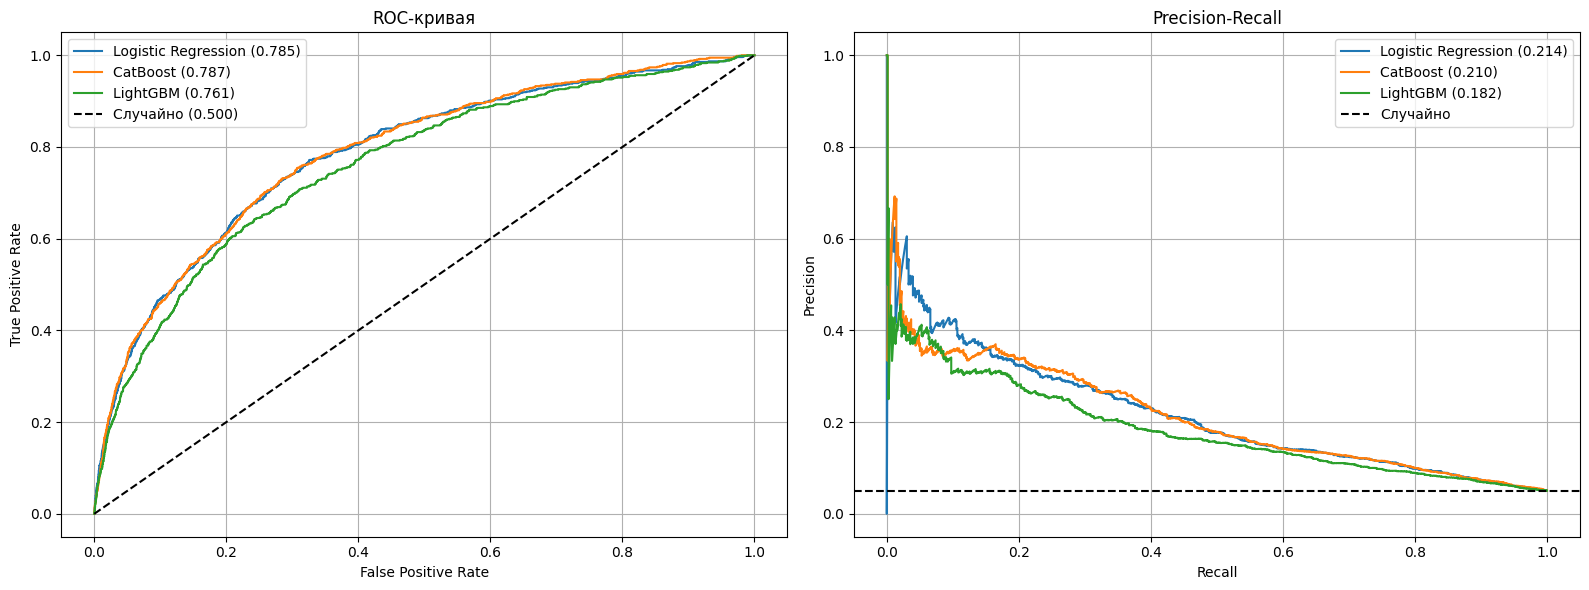

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for name, proba in predictions.items():
    fpr, tpr, _ = roc_curve(y_val, proba)
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_val, proba):.3f})")

    precision, recall, _ = precision_recall_curve(y_val, proba)
    ax2.plot(recall, precision, label=f"{name} ({auc(recall, precision):.3f})")

ax1.plot([0, 1], [0, 1], "k--", label="Случайно (0.500)")
ax1.set_title("ROC-кривая")
ax1.set_xlabel("False Positive Rate")
ax1.set_ylabel("True Positive Rate")

ax2.axhline(y_val.mean(), color="k", linestyle="--", label="Случайно")
ax2.set_title("Precision-Recall")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")

for ax in (ax1, ax2):
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

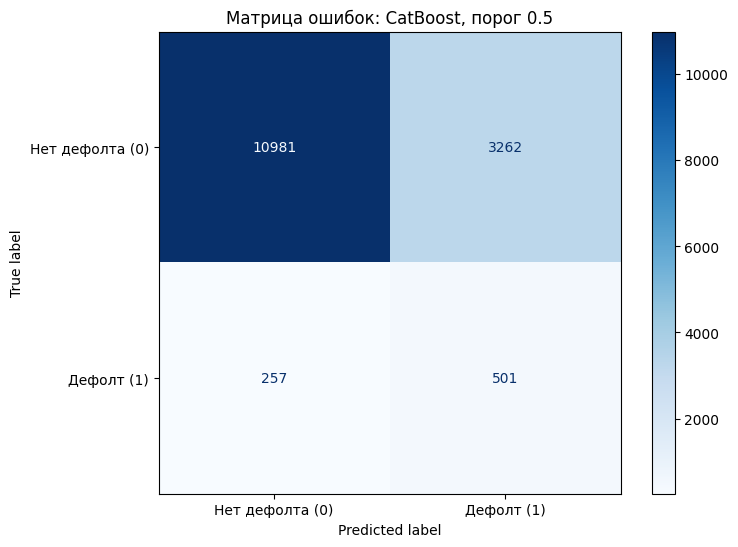

Precision: 0.133
Recall: 0.661


In [24]:
best_model_name = df_results.iloc[0]["Модель"]
best_proba = predictions[best_model_name]

# порог можно снизить, чтобы ловить больше дефолтов
THRESHOLD = 0.5
y_pred = (best_proba >= THRESHOLD).astype(int)

cm = confusion_matrix(y_val, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay(cm, display_labels=["Нет дефолта (0)", "Дефолт (1)"]).plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title(f"Матрица ошибок: {best_model_name}, порог {THRESHOLD}")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Precision: {tp / (tp + fp):.3f}")
print(f"Recall: {tp / (tp + fn):.3f}")

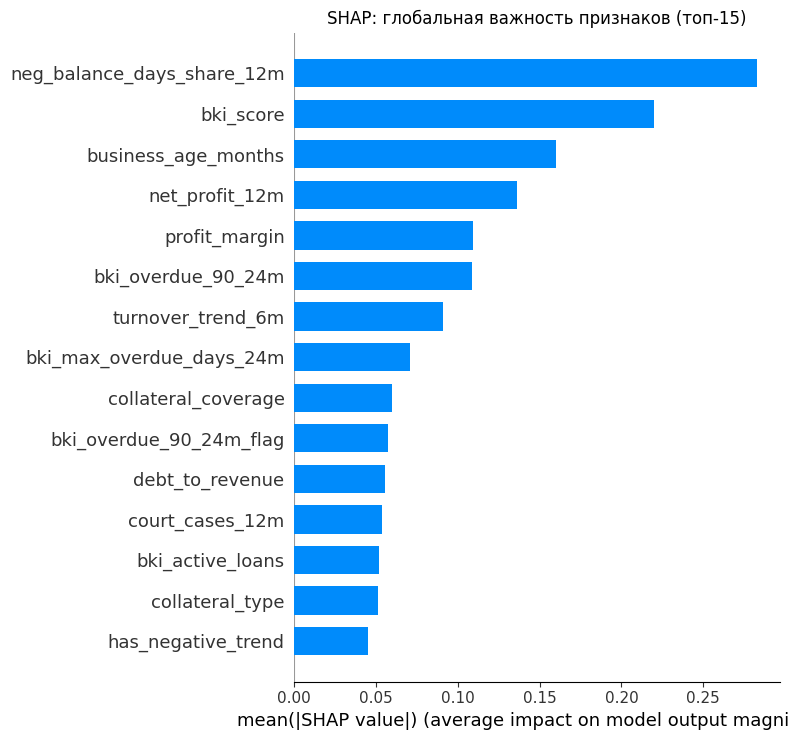

In [25]:
cb_model = models["CatBoost"]
explainer = shap.TreeExplainer(cb_model)
X_val_sample = X_val.sample(n=500, random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_val_sample)

shap.summary_plot(shap_values, X_val_sample, plot_type="bar", max_display=15, show=False)
plt.title("SHAP: глобальная важность признаков (топ-15)")
plt.tight_layout()
plt.show()

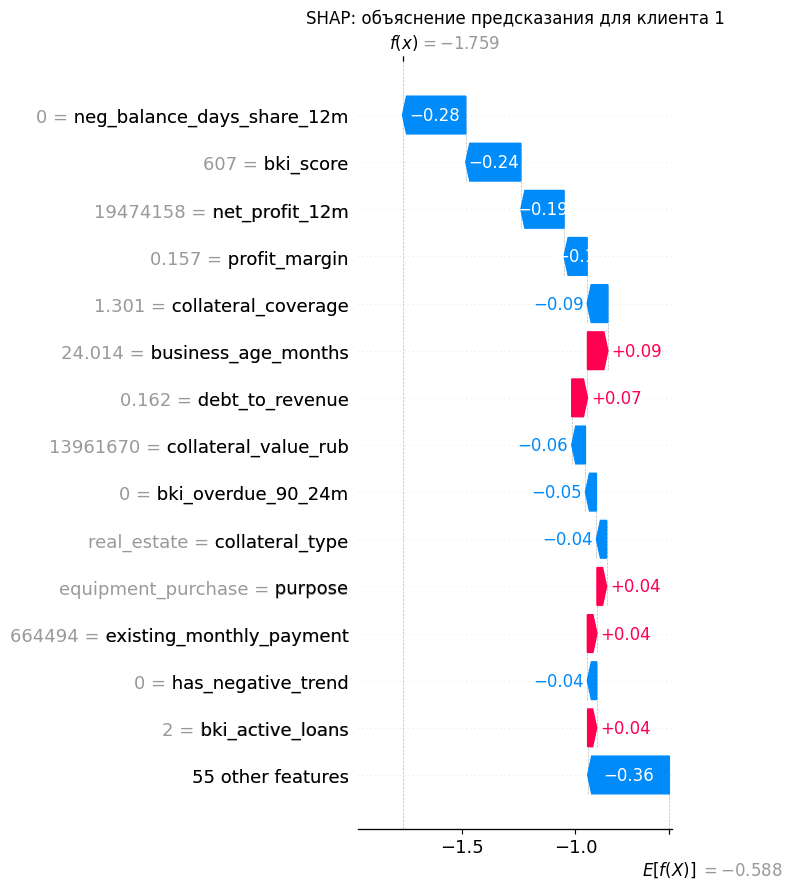

In [26]:
client_idx = 1

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[client_idx],
        base_values=explainer.expected_value,
        data=X_val_sample.iloc[client_idx],
        feature_names=X_val_sample.columns.tolist(),
    ),
    max_display=15,
    show=False,
)
plt.title(f"SHAP: объяснение предсказания для клиента {client_idx}")
plt.tight_layout()
plt.show()